In [47]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# Load the CSV file
series_post = pd.read_csv("../basketballPlayoffs/series_post.csv")

In [49]:
# List of categorical columns
categorical_cols = ["year", "round", "series", "tmIDWinner", "lgIDWinner", "tmIDLoser", "lgIDLoser"]

# Unique values per categorical column
print("\nUnique Values per Categorical Column:")
for col in categorical_cols:
    print(f"{col}: {series_post[col].nunique()} unique values")

# Value counts for key categorical columns
print("\nValue Counts for 'series':")
print(series_post['series'].value_counts())

print("\nTop Teams Wins:")
print(series_post['tmIDWinner'].value_counts())

print("\nTop Teams Losses:")
print(series_post['tmIDLoser'].value_counts())





Unique Values per Categorical Column:
year: 10 unique values
round: 3 unique values
series: 7 unique values
tmIDWinner: 14 unique values
lgIDWinner: 1 unique values
tmIDLoser: 18 unique values
lgIDLoser: 1 unique values

Value Counts for 'series':
series
A    10
B    10
C    10
D    10
E    10
F    10
G    10
Name: count, dtype: int64

Top Teams Wins:
tmIDWinner
LAS    12
DET    12
SAC     8
NYL     7
CON     6
PHO     6
HOU     4
IND     4
SEA     3
SAS     3
CHA     2
CLE     1
WAS     1
UTA     1
Name: count, dtype: int64

Top Teams Losses:
tmIDLoser
SAC    7
LAS    7
NYL    7
CON    6
IND    6
SEA    6
HOU    5
WAS    5
DET    4
SAS    3
CLE    3
CHA    3
UTA    2
MIN    2
ORL    1
MIA    1
PHO    1
ATL    1
Name: count, dtype: int64


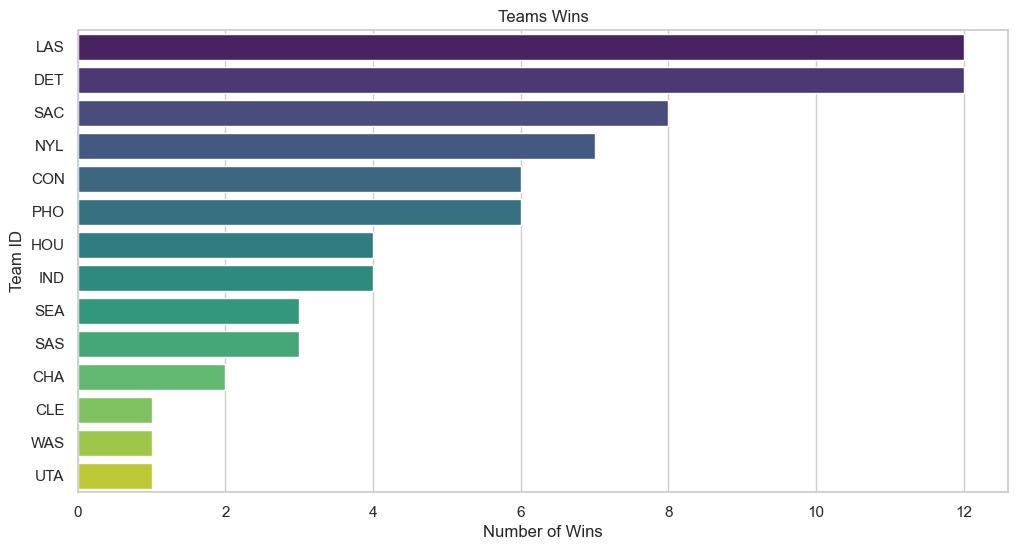

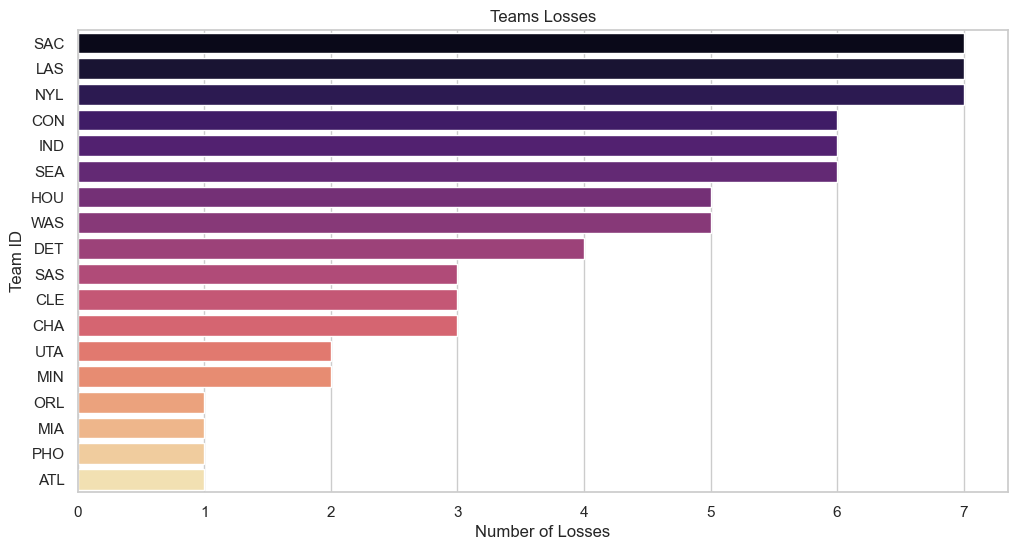

In [50]:
# Teams Wins
top_wins = wins_by_team
plt.figure(figsize=(12,6))
sns.barplot(x=top_wins.values, y=top_wins.index, palette="viridis")
plt.xlabel('Number of Wins')
plt.ylabel('Team ID')
plt.title('Teams Wins')
plt.show()

# Top 10 Teams with Most Losses
top_losses = losses_by_team
plt.figure(figsize=(12,6))
sns.barplot(x=top_losses.values, y=top_losses.index, palette="magma")
plt.xlabel('Number of Losses')
plt.ylabel('Team ID')
plt.title('Teams Losses')
plt.show()



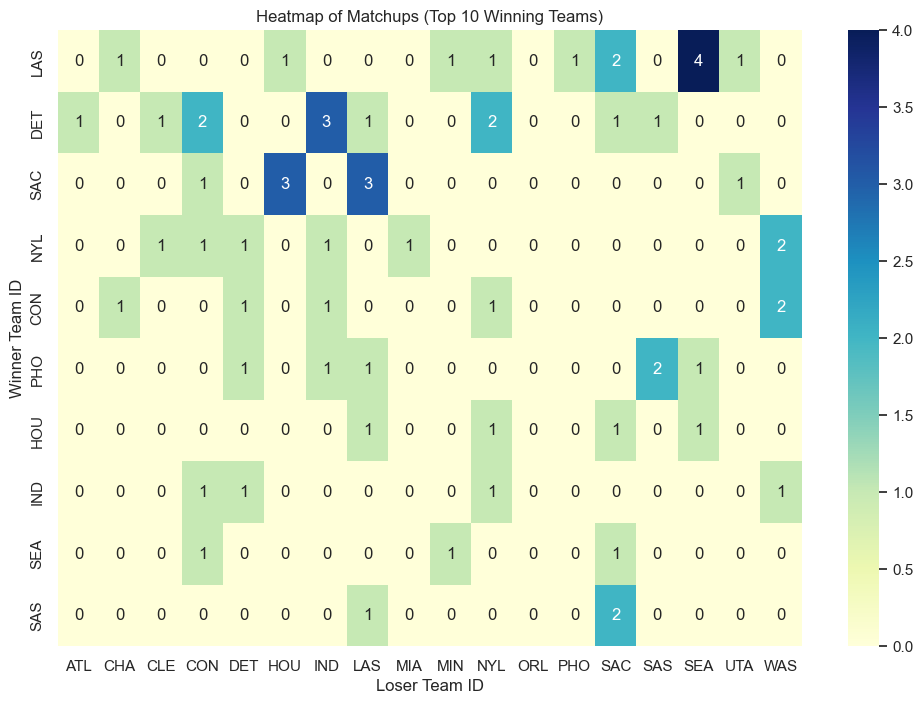

In [51]:
# Select top 10 teams by number of wins for the heatmap
top_teams = wins_by_team.head(10).index
filtered_crosstab = matchup_crosstab.loc[top_teams]

plt.figure(figsize=(12,8))
sns.heatmap(filtered_crosstab, annot=True, fmt='d', cmap='YlGnBu')
plt.xlabel('Loser Team ID')
plt.ylabel('Winner Team ID')
plt.title('Heatmap of Matchups (Top 10 Winning Teams)')
plt.show()



Win Percentage by Team:
PHO    0.857143
DET    0.750000
LAS    0.631579
SAC    0.533333
CON    0.500000
dtype: float64


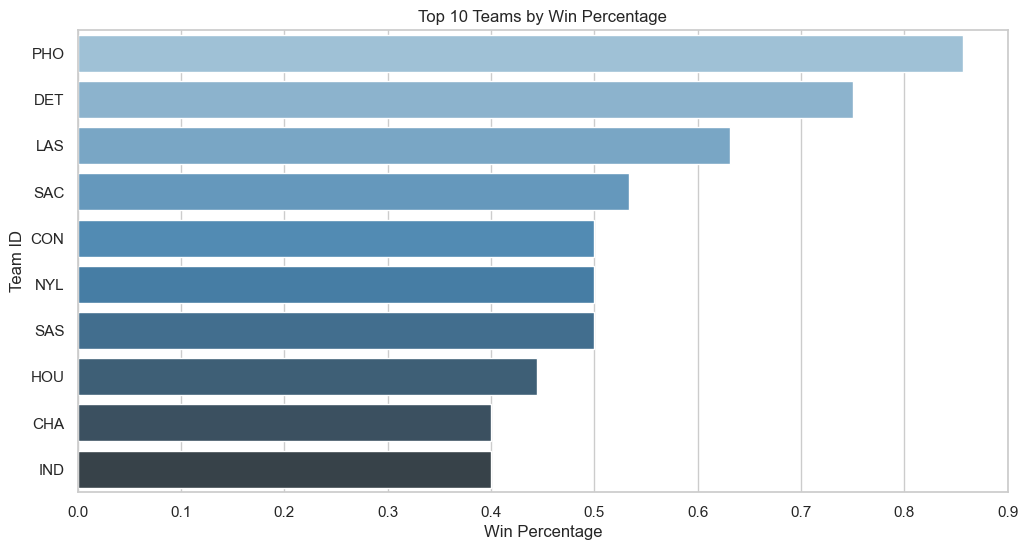

In [52]:
# Calculate total games played per team
total_games = series_post.groupby('tmIDWinner').size() + series_post.groupby('tmIDLoser').size()

# Calculate win percentage
win_percentage = (wins_by_team / total_games).sort_values(ascending=False)

print("\nWin Percentage by Team:")
print(win_percentage.head())

# Plot Top 10 Teams by Win Percentage
top_win_pct = win_percentage.head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=top_win_pct.values, y=top_win_pct.index, palette="Blues_d")
plt.xlabel('Win Percentage')
plt.ylabel('Team ID')
plt.title('Top 10 Teams by Win Percentage')
plt.show()



In [53]:
# Group by team (both winner and loser) and round, then count occurrences

# For teams that won each round
winner_rounds = series_post.groupby(['tmIDWinner', 'round']).size().unstack(fill_value=0)

# For teams that lost each round
loser_rounds = series_post.groupby(['tmIDLoser', 'round']).size().unstack(fill_value=0)

# Rename columns to reflect winning and losing rounds for clarity
winner_rounds.columns = [f'{col}_Wins' for col in winner_rounds.columns]
loser_rounds.columns = [f'{col}_Losses' for col in loser_rounds.columns]

# Combine the results to get the total rounds reached by each team
rounds_reached = pd.concat([winner_rounds, loser_rounds], axis=1).fillna(0)

# Reorder columns
desired_order = ['FR_Wins', 'CF_Wins', 'F_Wins', 'FR_Losses', 'CF_Losses', 'F_Losses']
rounds_reached = rounds_reached[desired_order]

# Format values to show as integers without decimal places
rounds_reached = rounds_reached.astype(int)

# Display the formatted DataFrame
print("Rounds Reached by Each Team (Wins and Losses) in Desired Order:")
print(rounds_reached)


Rounds Reached by Each Team (Wins and Losses) in Desired Order:
     FR_Wins  CF_Wins  F_Wins  FR_Losses  CF_Losses  F_Losses
CHA        1        1       0          2          0         1
CLE        1        0       0          2          1         0
CON        4        2       0          2          2         2
DET        5        4       3          2          1         1
HOU        2        1       1          4          1         0
IND        3        1       0          3          2         1
LAS        7        3       2          2          4         1
NYL        5        2       0          2          3         2
PHO        2        2       2          1          0         0
SAC        5        2       1          3          3         1
SAS        2        1       0          1          1         1
SEA        1        1       1          6          0         0
UTA        1        0       0          1          1         0
WAS        1        0       0          4          1         0
ATL   

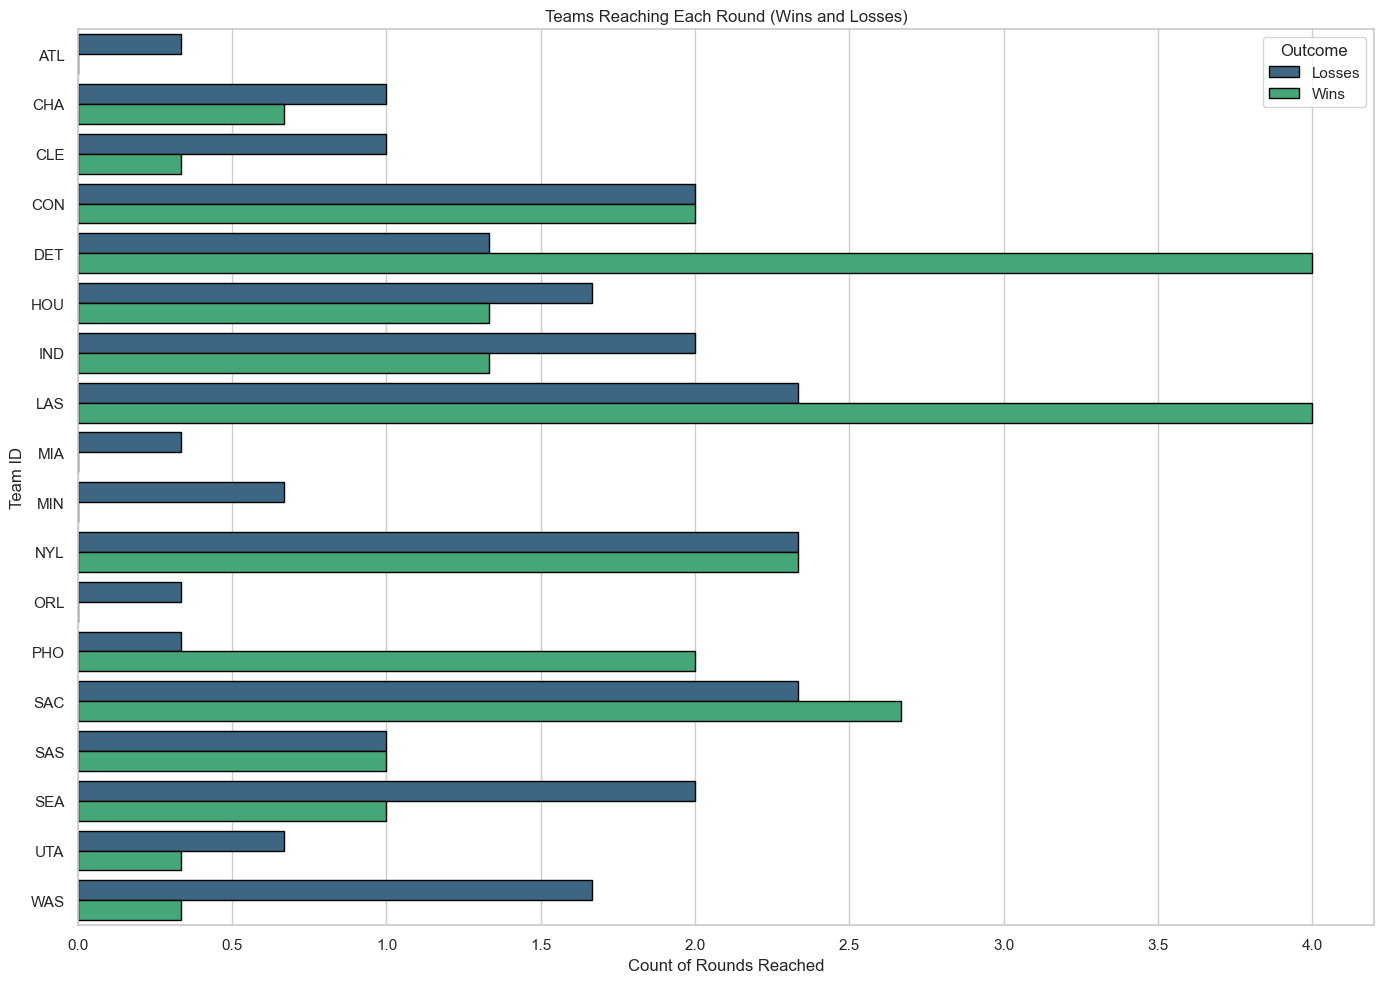

In [58]:
# Assume `rounds_reached` is already prepared, formatted as integers, and columns are in the desired order
# Reshape the data to long format for easier plotting with Seaborn
rounds_reached_long = rounds_reached.reset_index().melt(id_vars='index', 
                                                        var_name='Round_Outcome', 
                                                        value_name='Count')

# Split 'Round_Outcome' into separate 'Round' and 'Outcome' (Wins/Losses)
rounds_reached_long[['Round', 'Outcome']] = rounds_reached_long['Round_Outcome'].str.split('_', expand=True)

# Rename 'index' to 'Team' for clarity
rounds_reached_long = rounds_reached_long.rename(columns={'index': 'Team'})

# Sort values for cleaner plotting (optional)
rounds_reached_long = rounds_reached_long.sort_values(by=['Team', 'Round', 'Outcome'])

# Plotting
plt.figure(figsize=(14, 10))
sns.barplot(data=rounds_reached_long, x='Count', y='Team', hue='Outcome', 
            palette="viridis", edgecolor='black', orient='h', errorbar=None)

# Customize plot appearance
plt.title('Teams Reaching Each Round (Wins and Losses)')
plt.xlabel('Count of Rounds Reached')
plt.ylabel('Team ID')
plt.legend(title='Outcome', loc='upper right')
plt.tight_layout()

plt.show()

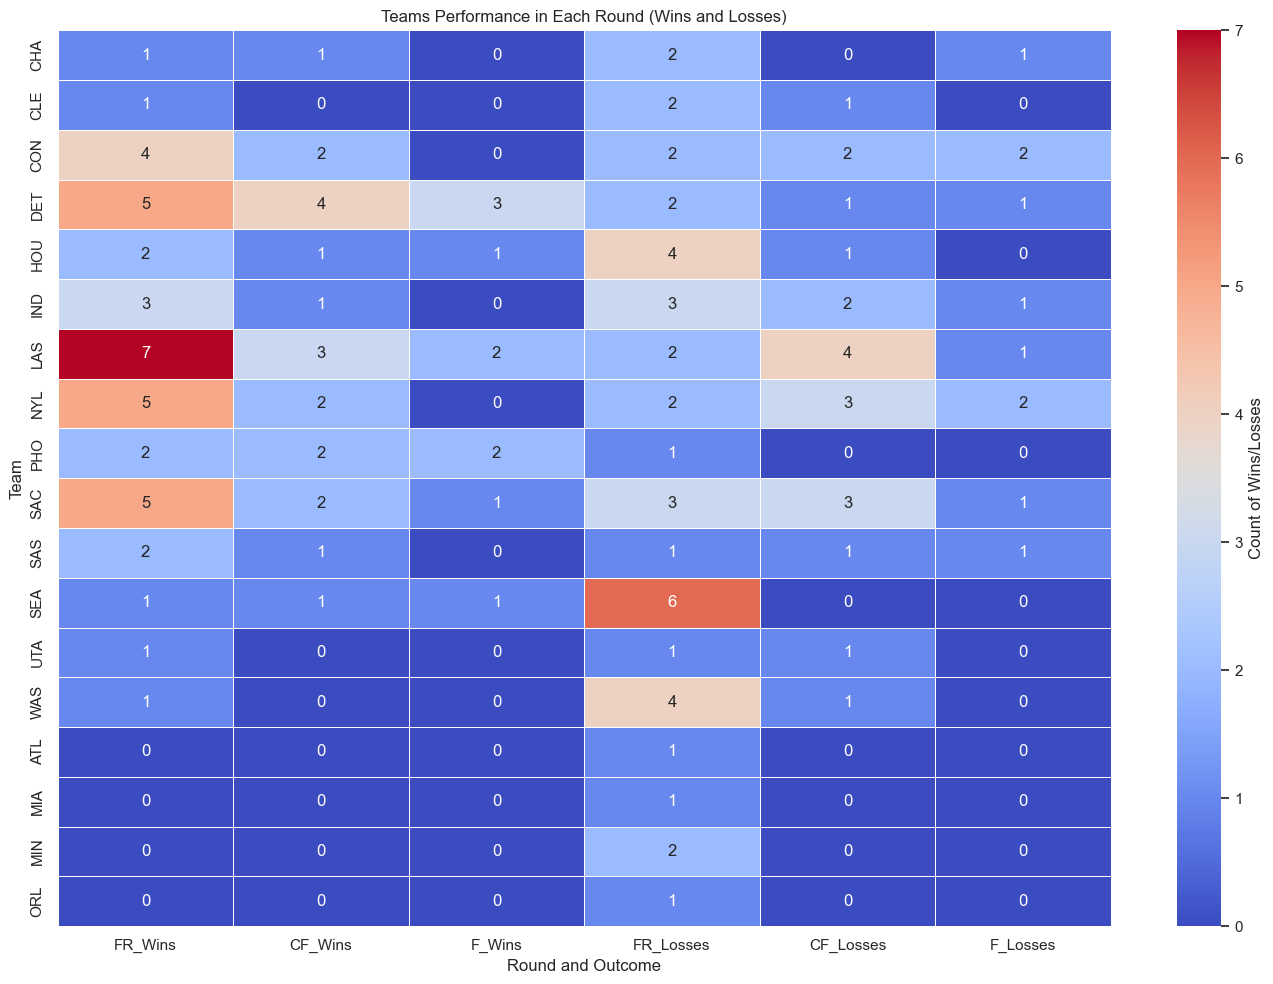

In [62]:
# Plotting a heatmap of the rounds_reached DataFrame
plt.figure(figsize=(14, 10))
sns.heatmap(rounds_reached, annot=True, cmap='coolwarm', fmt='d', linewidths=0.5, cbar_kws={'label': 'Count of Wins/Losses'})

# Adding title and labels for clarity
plt.title('Teams Performance in Each Round (Wins and Losses)')
plt.xlabel('Round and Outcome')
plt.ylabel('Team')
plt.tight_layout()

# Display the plot
plt.show()

Total Times Each Team Reached Each Round (Wins + Losses):
round  FR  CF  F
ATL     1   0  0
CHA     3   1  1
CLE     3   1  0
CON     6   4  2
DET     7   5  4
HOU     6   2  1
IND     6   3  1
LAS     9   7  3
MIA     1   0  0
MIN     2   0  0
NYL     7   5  2
ORL     1   0  0
PHO     3   2  2
SAC     8   5  2
SAS     3   2  1
SEA     7   1  1
UTA     2   1  0
WAS     5   1  0


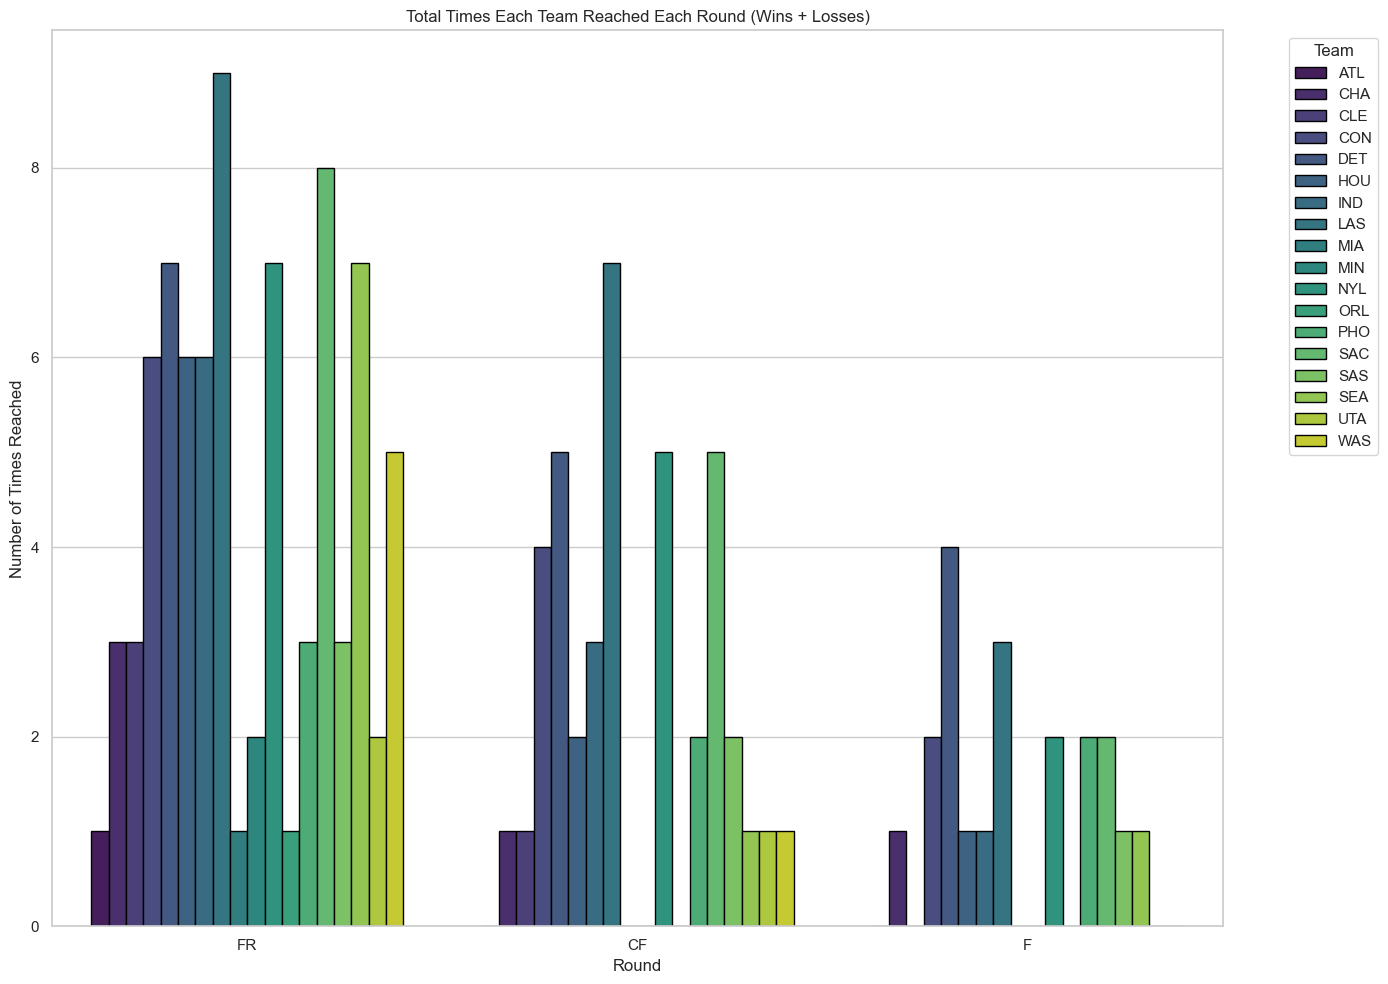

In [64]:
# Group by team and round, then count occurrences (both wins and losses combined)
# For winners
winner_rounds = series_post.groupby(['tmIDWinner', 'round']).size().unstack(fill_value=0)
# For losers
loser_rounds = series_post.groupby(['tmIDLoser', 'round']).size().unstack(fill_value=0)

# Combine the results: sum of wins and losses for each team and each round
total_rounds_reached = winner_rounds.add(loser_rounds, fill_value=0)

# Reorder columns to have rounds FR, CF, F
total_rounds_reached = total_rounds_reached[['FR', 'CF', 'F']]

# Convert to integer values (round the counts if necessary)
total_rounds_reached = total_rounds_reached.astype(int)

# Display the formatted DataFrame
print("Total Times Each Team Reached Each Round (Wins + Losses):")
print(total_rounds_reached)

# Reshaping for plotting
total_rounds_reached_long = total_rounds_reached.reset_index().melt(id_vars='index', 
                                                                  var_name='Round', 
                                                                  value_name='Count')

# Rename 'index' to 'Team' for clarity
total_rounds_reached_long = total_rounds_reached_long.rename(columns={'index': 'Team'})

# Plotting
plt.figure(figsize=(14, 10))
sns.barplot(data=total_rounds_reached_long, x='Round', y='Count', hue='Team', 
            palette="viridis", edgecolor='black', errorbar=None)

# Customize plot appearance
plt.title('Total Times Each Team Reached Each Round (Wins + Losses)')
plt.xlabel('Round')
plt.ylabel('Number of Times Reached')
plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left')

# Display the plot
plt.tight_layout()
plt.show()

In [66]:
# Assuming rounds_reached is already created and contains wins and losses

# For winners (already calculated)
winner_rounds = series_post.groupby(['tmIDWinner', 'round']).size().unstack(fill_value=0)

# For losers (already calculated)
loser_rounds = series_post.groupby(['tmIDLoser', 'round']).size().unstack(fill_value=0)

# Combine the results: sum of wins and losses for each team and each round
total_rounds_reached = winner_rounds.add(loser_rounds, fill_value=0)

# Reorder columns to have rounds FR, CF, F
total_rounds_reached = total_rounds_reached[['FR', 'CF', 'F']]

# Convert to integer values (round the counts if necessary)
total_rounds_reached = total_rounds_reached.astype(int)

# Now, add total reached per round (sum of wins + losses) for each round separately
rounds_reached['Total_FR'] = rounds_reached['FR_Wins'] + rounds_reached['FR_Losses']
rounds_reached['Total_CF'] = rounds_reached['CF_Wins'] + rounds_reached['CF_Losses']
rounds_reached['Total_F'] = rounds_reached['F_Wins'] + rounds_reached['F_Losses']

# Display the updated DataFrame
print("Updated Rounds Reached by Each Team (Including Separate Total Reached for Each Round):")
print(rounds_reached)

Updated Rounds Reached by Each Team (Including Separate Total Reached for Each Round):
     FR_Wins  CF_Wins  F_Wins  FR_Losses  CF_Losses  F_Losses  Total_Reached  \
CHA        1        1       0          2          0         1              5   
CLE        1        0       0          2          1         0              4   
CON        4        2       0          2          2         2             12   
DET        5        4       3          2          1         1             16   
HOU        2        1       1          4          1         0              9   
IND        3        1       0          3          2         1             10   
LAS        7        3       2          2          4         1             19   
NYL        5        2       0          2          3         2             14   
PHO        2        2       2          1          0         0              7   
SAC        5        2       1          3          3         1             15   
SAS        2        1       0    